# Shut-down — cool-down rates, forced cooling and gas sequence (all 39 days)

**Shut-down** takes the plant from load or Hot standby down to room temperature and keeps it there until the next
Start-up (`../01_docs/operational-modes.md` §1, §3.3). The library labels every Shut-down minute with a sub-stage
(`sub_stage`):

| Sub-stage | What it contains | Test |
|---|---|---|
| **Cooling** | load ramp-down to zero, forced cooling (air on), natural cooling (air off) while the stack is still warm | Shut-down, stack > ambient + 30 K |
| **At ambient (plant off)** | plant off, waiting for the next Start-up | plant off, stack ≤ ambient + 30 K |

Ambient is the median of the supply-line probes `TIR_1_1_1`, `TIR_1_2_1`, `TIR_1_3`, `TIR_1_4_1`, so the end of
Cooling sits at about 40–48 °C (this replaces the old fixed 50 °C end point).

A no-load fall of a hot stack that levels off again (*Cool-back (no load)*, *Temperature dip during hold*) is **not**
Shut-down: it is the stage **Thermal adjustment**, together with the re-heats. See
[`thermal_adjustment_analysis.ipynb`](thermal_adjustment_analysis.ipynb). A cool-back that runs straight into a
cool-down is the start of that Shut-down.

The library episodes split into two kinds:

| Kind | Test |
|---|---|
| **Cool-down** | contains an active cooling operation (*Cool-down (air flow on)*, *Slow cool-down*, *Controlled cool-down*) |
| **Plant off** | only *Natural cooling (air off)* and / or *Plant off at ambient*: the plant-off hours, studied in `cold_idle_analysis.ipynb` |

This notebook covers:

2. **Inventory**: every Shut-down episode, its kind and sub-stages, what came before and after, and safety trips.
3. **What the hours contain**: minutes per operation and sub-stage, how a shut-down begins, and where Cooling ends.
4. **Cool-down rate**: band rates, the 120 °C/h limit, and the coldest thermocouple.
5. **Forced-cooling physics**: time constant with air on, and how it depends on the air flow.
6. **Air, gas and heater sequence** on the way down, and the temperature at which the air goes off.
7. **Thermal gradient** while cooling.
8. **Timings**, and 9. **signal levels by temperature band** (input for synthetic data).

**Data:** labels and episodes from `04_synthetic_data/library/` (rebuilt 2026-10-14), extra signals from
`02_data/downsampled/*_10s.parquet` via `stage_signals.py` at 1 min, safety events from
`operating_states/trip_cut_events.csv` (`trip_check.py`). Tables and figures are saved to `shutdown/`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, "scripts")  # helper modules live in 03_data_analysis/scripts/
import operating_states as ops
import stage_signals as ss

pd.set_option("display.max_rows", 120)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)

OUT = Path("shutdown")
OUT.mkdir(exist_ok=True)
LIMIT = 120.0  # °C/h, cool-down limit (operational-modes.md §4.5)
TAU_NATURAL_H = 89  # natural cooling, heater and air off (cold_idle_analysis.ipynb §5)
ACTIVE = (
    "Cool-down (air flow on)",
    "Slow cool-down",
    "Controlled cool-down (heater trim)",
)
KIND_COLORS = {"Cool-down": "#2a78d6", "Plant off": "#9aa5b1"}
SUB = [ops.SD_COOLING, ops.SD_AMBIENT]
plt.rcParams.update(
    {
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.25,
        "lines.linewidth": 1.4,
        "font.size": 9,
    }
)

## 1. Load labels, signals, episodes and safety events

Same loader as the start-up notebook (`stage_signals.load()`): robust thermocouple spread without `TIR_4_6_25`, and
the three logger-dropout minutes blanked so they do not show up as fake rates.

In [2]:
d = ss.load()
e = ss.neighbours(ss.episodes())
assert not e.operations.str.contains("Cool-down to Hot standby").any()
sd = e[e.stage == "Shut-down"].copy()
sd["kind"] = np.where(
    sd.operations.str.split(" > ").apply(lambda o: any(x in ACTIVE for x in o)),
    "Cool-down",
    "Plant off",
)
d["kind"] = d.episode_id.map(sd.set_index("episode_id").kind)
s = d[d.stage == "Shut-down"]
assert not s.operation.isin(ops.COOL_BACK_OPS).any()
sd["T_start_C"] = sd.episode_id.map(s.groupby("episode_id").T_stack_C.first())
sd["T_end_C"] = sd.episode_id.map(s.groupby("episode_id").T_stack_C.last())
sd["T_min_C"] = sd.episode_id.map(s.groupby("episode_id").T_stack_C.min())
for k, n in ((ops.SD_COOLING, "cooling_h"), (ops.SD_AMBIENT, "at_ambient_h")):
    sd[n] = (
        sd.episode_id.map(s[s.sub_stage == k].groupby("episode_id").size() / 60)
        .fillna(0)
        .round(2)
    )
tev = ss.all_cuts()
tev["time"] = pd.to_datetime(tev["time"])
# forced-cooling minutes: air on, heater off, no current
forced = (
    (s.air_flow > 50)
    & (s.P_EAPH_kW < ops.EAPH_ON_W / 1000)
    & (s.I_string_A < ops.I_LOAD)
)
print(
    f"{len(s):,} Shut-down minutes ({len(s) / 60:.0f} h, {len(s) / len(d):.0%} of "
    f"logged time) in {len(sd)} episodes; "
    f"{forced.sum() / 60:.0f} h forced cooling (air on, heater off)"
)
sub_h = (
    s.groupby(["sub_stage", "kind"])
    .size()
    .unstack(fill_value=0)
    .reindex(index=SUB, columns=list(KIND_COLORS), fill_value=0)
    / 60
)
sub_h["total_h"] = sub_h.sum(axis=1)
print(sd.kind.value_counts().to_string())
sub_h.round(1)

23,131 Shut-down minutes (386 h, 42% of logged time) in 19 episodes; 249 h forced cooling (air on, heater off)
kind
Cool-down    11
Plant off     8


kind,Cool-down,Plant off,total_h
sub_stage,,,
Cooling,281.2,26.7,307.9
At ambient (plant off),20.5,57.1,77.6


## 2. Inventory of Shut-down episodes

`trip_initiated` = a safety event (EMERGENCY STOP / PURGE, power cut at trip value) inside the episode or just
before it, from the library's fault flags; `fault_events` lists them. `T_min_C` is the coldest stack median reached.
`cooling_h` / `at_ambient_h` = hours in each sub-stage.

In [3]:
inv = sd[
    [
        "episode_id",
        "kind",
        "start",
        "end",
        "duration_h",
        "cooling_h",
        "at_ambient_h",
        "T_start_C",
        "T_min_C",
        "T_end_C",
        "prev_stage",
        "next_stage",
        "trip_initiated",
        "operations",
        "fault_events",
    ]
].copy()
inv[inv.select_dtypes("number").columns] = inv.select_dtypes("number").round(2)
inv.to_csv(OUT / "episodes.csv", index=False)
inv.drop(columns=["fault_events"])

,episode_id,kind,start,end,duration_h,cooling_h,at_ambient_h,T_start_C,T_min_C,T_end_C,prev_stage,next_stage,trip_initiated,operations
3,20251113_0000_Shut-down,Plant off,2025-11-13 00:00:00,2025-11-13 10:47:00,10.78,0.00,10.78,10.18,9.85,10.10,file edge,Start-up,False,Plant off at ambient
5,20251113_2132_Shut-down,Cool-down,2025-11-13 21:32:00,2025-11-19 00:00:00,122.47,106.00,16.47,471.67,22.60,22.64,Start-up,file edge,False,Slow cool-down > Cool-down (air flow on) > Pla...
6,20260130_0000_Shut-down,Plant off,2026-01-30 00:00:00,2026-01-30 10:10:00,10.17,0.00,10.17,6.10,3.40,4.03,file edge,Start-up,False,Plant off at ambient
8,20260130_1910_Shut-down,Cool-down,2026-01-30 19:10:00,2026-01-31 08:09:00,12.98,12.98,0.00,240.35,175.08,175.08,Start-up,Start-up,False,Cool-down (air flow on) > Natural cooling (air...
15,20260204_0201_Shut-down,Cool-down,2026-02-04 02:01:00,2026-02-06 13:27:00,59.43,55.37,4.07,508.94,45.26,45.28,Hot standby,Start-up,False,Cool-down (air flow on) > Plant off at ambient
17,20260213_0000_Shut-down,Plant off,2026-02-13 00:00:00,2026-02-13 14:32:00,14.53,0.00,14.53,14.98,13.90,14.53,file edge,Start-up,False,Plant off at ambient
20,20260216_1037_Shut-down,Cool-down,2026-02-16 10:37:00,2026-02-17 16:56:00,30.32,30.32,0.00,509.56,190.34,191.12,Hot standby,Start-up,False,Cool-down (air flow on) > Natural cooling (air...
25,20260218_1726_Shut-down,Cool-down,2026-02-18 17:26:00,2026-02-19 00:00:00,5.60,5.60,0.00,600.43,442.38,442.38,Hot standby,file edge,False,Cool-down (air flow on)
26,20260301_0000_Shut-down,Plant off,2026-03-01 00:00:00,2026-03-01 09:05:00,9.08,0.00,9.08,29.37,27.61,27.64,file edge,Start-up,False,Plant off at ambient
35,20260304_1756_Shut-down,Cool-down,2026-03-04 17:56:00,2026-03-05 00:00:00,6.07,6.07,0.00,613.62,336.31,336.31,Hot standby,file edge,False,Cool-down (air flow on)


## 3. What the Shut-down hours contain, and how a shut-down begins

In [4]:
opm = (
    s.groupby(["operation", "sub_stage"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=SUB, fill_value=0)
)
opm["hours"] = (opm.sum(axis=1) / 60).round(1)
opm = opm.sort_values("hours", ascending=False)
opm.to_csv(OUT / "operations.csv")
opm

sub_stage,Cooling,At ambient (plant off),hours
operation,,,
Cool-down (air flow on),14900,0,248.3
Plant off at ambient,0,4659,77.6
Natural cooling (air off),3165,0,52.8
Slow cool-down,299,0,5.0
Controlled cool-down (heater trim),77,0,1.3
"Temperature rise, heater off",22,0,0.4
Load ramp-down to zero,9,0,0.2


In [5]:
cd = sd[sd.kind == "Cool-down"]
print("stage before each cool-down, and the operations of that stage")
pd.crosstab(
    [cd.prev_stage, cd.prev_ops.str.split(" > ").str[-1]],
    cd.trip_initiated.map({True: "trip", False: "no trip"}),
)

stage before each cool-down, and the operations of that stage


trip_initiated                                     no trip  trip
prev_stage         prev_ops                                     
Hot standby        Low-temperature hold (~510 °C)        2     0
                   Temperature hold                      2     0
Part load          Load ramp-up                          0     1
                   Steady load                           0     2
Start-up           Heat-up paused (heater off)           1     0
                   Intermediate hold (~510 °C)           1     0
Thermal adjustment Re-heat (no load)                     2     0

**Where Cooling ends.** Each switch from Cooling to *At ambient (plant off)*: the stack median and the ambient proxy
at the first At-ambient minute (the threshold is ambient + 30 K), and how long the Cooling sub-stage lasted before it.
Only switches inside the logged data count; a day file that starts at ambient is not a switch.

In [6]:
sw = (
    (s.sub_stage == ops.SD_AMBIENT)
    & (s.sub_stage.shift() == ops.SD_COOLING)
    & (s.index.to_series().diff() == pd.Timedelta("1min"))
)
amb = pd.DataFrame(
    {
        "episode_id": s.episode_id[sw],
        "T_stack_C": s.T_stack_C[sw],
        "T_amb_C": s.T_amb_C[sw],
    }
)
amb["excess_K"] = amb.T_stack_C - amb.T_amb_C
amb["cooling_h_before"] = amb.episode_id.map(sd.set_index("episode_id").cooling_h)
amb.round(1)

,episode_id,T_stack_C,T_amb_C,excess_K,cooling_h_before
2025-11-18 07:32:00,20251113_2132_Shut-down,24.7,15.8,8.9,106.0
2026-02-06 09:23:00,20260204_0201_Shut-down,46.3,17.0,29.3,55.4
2026-03-28 09:41:00,20260328_0000_Shut-down,38.1,8.1,30.0,9.7


**Safety events inside cool-downs.** Every event `trip_check.py` found between the first and last minute of a
Cool-down episode (and up to 15 min before it), with its kind and the stack temperature.

In [7]:
rows = []
for _, r in cd.iterrows():
    w = tev[(tev.time >= r.start - pd.Timedelta("15min")) & (tev.time <= r.end)]
    for _, t in w.iterrows():
        rows.append(
            {
                "episode_id": r.episode_id,
                "time": t.time,
                "kind": t.kind,
                "T_stack_C": t["T stack °C"],
                "trip_value": t["trip value exceeded (60 s before)"],
            }
        )
ev = pd.DataFrame(rows)
ev.to_csv(OUT / "safety_events.csv", index=False)
ev

,episode_id,time,kind,T_stack_C,trip_value
0,20260216_1037_Shut-down,2026-02-16 10:23:50,"Load / heater off, valves unchanged",514,-
1,20260216_1037_Shut-down,2026-02-17 07:39:16,Valve change only,213,-
2,20260216_1037_Shut-down,2026-02-17 16:36:52,Valve change only,197,-
3,20260313_1343_Shut-down,2026-03-13 13:45:15,"Power cut at trip value, gas unchanged",695,TIRZ_8_1_10 202 > 200
4,20260319_1549_Shut-down,2026-03-19 15:54:35,"Power cut at trip value, gas unchanged",661,TIRZ_8_1_10 201 > 200
5,20260319_1549_Shut-down,2026-03-20 06:23:35,"Load / heater off, valves unchanged",467,-
6,20260325_1514_Shut-down,2026-03-25 15:18:26,"Gas to purge, heater kept on",701,-
7,20260325_1514_Shut-down,2026-03-25 15:28:17,EMERGENCY STOP,689,-
8,20260325_1514_Shut-down,2026-03-26 09:45:25,Valve change only,43,-
9,20260330_1333_Shut-down,2026-03-30 13:18:15,Valve change only,636,-


## 4. Cool-down rate

### 4.1 Band rates

Time between the **last** downward crossings of each band by the stack median (as in `operational-modes.md` §4.5),
for every Cool-down episode. A blank means the band was not crossed downward inside the episode.

In [8]:
BANDS = [(500, 600), (400, 500), (300, 400), (200, 300), (100, 200), (50, 100)]
rows = []
for _, r in cd.iterrows():
    g = d[d.episode_id == r.episode_id]
    rows.append(
        {
            "episode_id": r.episode_id,
            "air_flow_median": g.air_flow[g.air_flow > 50].median(),
            **ss.band_rates(
                g.T_stack_C.interpolate(limit=60), g.index, BANDS, rising=False
            ),
        }
    )
br = pd.DataFrame(rows).set_index("episode_id")
br.loc["median (all)"] = br.median()
br.round(1).to_csv(OUT / "band_rates.csv")
br.round(1)

,air_flow_median,600->500,500->400,400->300,300->200,200->100,100->50
episode_id,,,,,,,
20251113_2132_Shut-down,5999.5,NaN,NaN,-7.0,-4.7,-6.4,-2.6
20260130_1910_Shut-down,6000.0,NaN,NaN,NaN,NaN,NaN,NaN
20260204_0201_Shut-down,6000.1,NaN,-24.7,-19.2,-12.4,-6.2,-2.7
20260216_1037_Shut-down,6000.0,NaN,-24.3,-16.0,-6.9,NaN,NaN
20260218_1726_Shut-down,6000.0,-24.0,NaN,NaN,NaN,NaN,NaN
20260304_1756_Shut-down,8000.0,-53.1,-49.6,NaN,NaN,NaN,NaN
20260313_1343_Shut-down,6000.0,-24.6,NaN,NaN,NaN,NaN,NaN
20260319_1549_Shut-down,6000.0,-13.3,NaN,NaN,NaN,NaN,NaN
20260320_1624_Shut-down,10000.1,NaN,-61.9,-36.8,NaN,NaN,NaN


### 4.2 Rate during forced cooling, against the 120 °C/h limit

1-hour centred rate of the stack median and of the **coldest** thermocouple (the point that cools fastest) over the
forced-cooling minutes of each Cool-down episode.

In [9]:
fc = s[forced & (s.kind == "Cool-down")]
rate = fc.groupby("episode_id").agg(
    minutes=("T_stack_C", "size"),
    air_flow=("air_flow", "median"),
    median_rate=("dTdt_C_per_h", "median"),
    p5_rate=("dTdt_C_per_h", lambda x: x.quantile(0.05)),
    min_rate=("dTdt_C_per_h", "min"),
    coldest_tc_p5=("dTmindt_C_per_h", lambda x: x.quantile(0.05)),
    coldest_tc_min=("dTmindt_C_per_h", "min"),
)
rate["minutes_beyond_limit_coldest_tc"] = fc.groupby(
    "episode_id"
).dTmindt_C_per_h.apply(lambda x: int((x < -LIMIT).sum()))
rate.round(1).to_csv(OUT / "cooldown_rates.csv")
print(
    f"all {len(fc):,} forced-cooling minutes: median {fc.dTdt_C_per_h.median():.0f} "
    f"°C/h, p5 {fc.dTdt_C_per_h.quantile(0.05):.0f}, "
    f"coldest TC p5 {fc.dTmindt_C_per_h.quantile(0.05):.0f}, min "
    f"{fc.dTmindt_C_per_h.min():.0f} °C/h"
)
rate.round(1)

all 14,906 forced-cooling minutes: median -7 °C/h, p5 -52, coldest TC p5 -43, min -123 °C/h


,minutes,air_flow,median_rate,p5_rate,min_rate,coldest_tc_p5,coldest_tc_min,minutes_beyond_limit_coldest_tc
episode_id,,,,,,,,
20251113_2132_Shut-down,6361,5999.5,-2.6,-12.9,-30.9,-10.3,-40.1,0
20260130_1910_Shut-down,116,6000.0,-22.6,-28.6,-28.7,-31.7,-33.5,0
20260204_0201_Shut-down,3321,6000.1,-5.5,-23.5,-30.8,-19.3,-65.2,0
20260216_1037_Shut-down,1268,6000.0,-12.8,-26.7,-30.2,-22.7,-68.0,0
20260218_1726_Shut-down,307,6000.0,-26.7,-31.8,-32.3,-25.3,-25.7,0
20260304_1756_Shut-down,313,8000.0,-48.0,-65.6,-66.5,-83.6,-84.6,0
20260313_1343_Shut-down,559,6000.0,-23.6,-28.1,-30.2,-37.3,-42.6,0
20260319_1549_Shut-down,866,6000.0,-11.6,-24.2,-25.7,-23.9,-42.8,0
20260320_1624_Shut-down,250,10000.0,-52.7,-78.5,-79.1,-101.8,-112.1,0


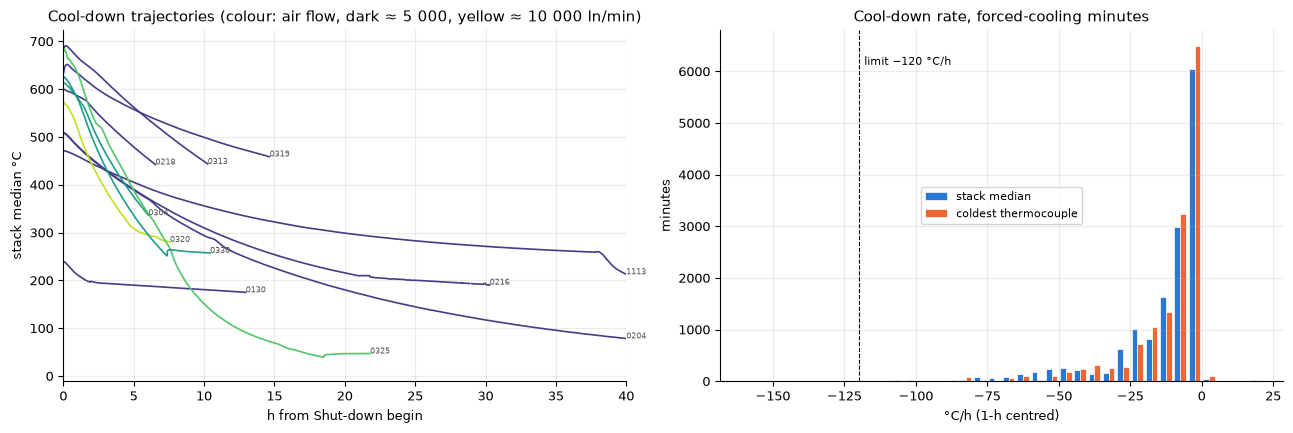

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
cmap = plt.get_cmap("viridis")
for _, r in cd.iterrows():
    g = d[d.episode_id == r.episode_id]
    h = (g.index - g.index[0]).total_seconds() / 3600
    af = g.air_flow[g.air_flow > 50].median()
    ax[0].plot(
        h,
        g.T_stack_C,
        color=cmap(min(max((af - 5000) / 5500, 0), 1)) if af == af else "#9aa5b1",
        lw=1.2,
    )
    ax[0].text(
        min(h[-1], 40),
        g.T_stack_C.iloc[-1] if h[-1] <= 40 else g.T_stack_C[h <= 40].iloc[-1],
        r.episode_id[4:8],
        fontsize=6,
        color="#555",
    )
ax[0].set_xlim(0, 40)
ax[0].set_xlabel("h from Shut-down begin")
ax[0].set_ylabel("stack median °C")
ax[0].set_title(
    "Cool-down trajectories (colour: air flow, dark ≈ 5 000, yellow ≈ 10 000 ln/min)"
)
bins = np.arange(-160, 21, 5)
ax[1].hist(
    [fc.dTdt_C_per_h.dropna(), fc.dTmindt_C_per_h.dropna()],
    bins=bins,
    color=["#2a78d6", "#eb6834"],
    label=["stack median", "coldest thermocouple"],
    edgecolor="white",
    linewidth=0.5,
)
ax[1].axvline(-LIMIT, color="k", lw=0.8, ls="--")
ax[1].text(-LIMIT + 2, ax[1].get_ylim()[1] * 0.9, "limit −120 °C/h", fontsize=8)
ax[1].set_xlabel("°C/h (1-h centred)")
ax[1].set_ylabel("minutes")
ax[1].legend(fontsize=8)
ax[1].set_title("Cool-down rate, forced-cooling minutes")
fig.tight_layout()
fig.savefig(OUT / "cooldown_rates.png", dpi=130)
plt.show()

## 5. Forced-cooling physics

With air on and the heater off, the air carries heat out of the stack on top of the insulation loss. If the stack
still follows Newton's law, ln(T − T_amb) falls on a straight line with slope −1/τ, as for natural cooling (τ ≈ 89 h,
plant-off notebook §5). The fit uses every forced-cooling stretch of ≥ 2 h inside a Shut-down episode (stack ≥ 50 °C,
air flow constant to the nearest 100 ln/min). `T_air_in` is the median cathode inlet `TIRC_2_06` during the stretch.
The second table groups the time constants by air flow.

In [11]:
ok = forced & (s.T_stack_C >= 50)
blk = (
    (ok != ok.shift())
    | (s.index.to_series().diff() != pd.Timedelta("1min"))
    | (s.air_flow.round(-2) != s.air_flow.round(-2).shift())
).cumsum()


def tau_fit(y, ta, h):
    z = np.log((y - ta).clip(lower=1))
    m = z.notna() & np.isfinite(z)
    p = np.polyfit(h[m], z[m], 1)
    return -1 / p[0], np.corrcoef(h[m], z[m])[0, 1] ** 2


fits = []
for k, g in s[ok].groupby(blk[ok]):
    if len(g) < 120:
        continue
    h = pd.Series((g.index - g.index[0]).total_seconds() / 3600, index=g.index)
    tau, r2 = tau_fit(g.T_stack_C, g.T_amb_C.mean(), h)
    fits.append(
        {
            "episode_id": g.episode_id.iat[0],
            "start": g.index[0],
            "hours": round(len(g) / 60, 1),
            "air_flow": g.air_flow.median(),
            "N2": g.N2.median(),
            "T_from_C": g.T_stack_C.iloc[0],
            "T_to_C": g.T_stack_C.iloc[-1],
            "T_air_in_C": g.TIRC_2_06.median(),
            "rate_C_per_h": (g.T_stack_C.iloc[-1] - g.T_stack_C.iloc[0]) / h.iloc[-1],
            "tau_h": tau,
            "R2": r2,
        }
    )
fits = pd.DataFrame(fits)
fits.round(2).to_csv(OUT / "forced_cooling_tau.csv", index=False)
fits.round(2)

C:\Users\mrgur\AppData\Local\Temp\ipykernel_14920\325719281.py:24: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  fits.round(2).to_csv(OUT / "forced_cooling_tau.csv", index=False)
C:\Users\mrgur\AppData\Local\Temp\ipykernel_14920\325719281.py:25: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  fits.round(2)


,episode_id,start,hours,air_flow,N2,T_from_C,T_to_C,T_air_in_C,rate_C_per_h,tau_h,R2
0,20251113_2132_Shut-down,2025-11-13 21:32:00,37.8,1259.83,1199.98,471.67,259.13,238.52,-5.62,62.24,0.94
1,20251113_2132_Shut-down,2025-11-15 11:40:00,38.1,6000.02,0.00,258.75,50.08,92.71,-5.48,20.01,1.00
2,20260204_0201_Shut-down,2026-02-04 02:01:00,6.2,5999.98,1199.96,508.94,367.78,375.26,-22.89,18.17,1.00
3,20260204_0201_Shut-down,2026-02-04 08:13:00,4.0,7999.90,1199.94,366.73,291.25,291.31,-19.03,16.69,1.00
4,20260204_0201_Shut-down,2026-02-04 12:13:00,42.2,6000.00,0.00,290.99,50.01,104.03,-5.71,20.29,1.00
5,20260216_1037_Shut-down,2026-02-16 10:37:00,21.0,6000.02,1199.97,509.56,209.46,271.38,-14.28,22.48,0.99
6,20260218_1726_Shut-down,2026-02-18 18:53:00,5.1,6000.02,1199.99,578.90,442.38,438.79,-26.77,18.20,1.00
7,20260304_1756_Shut-down,2026-03-04 18:47:00,5.2,7999.98,1200.03,588.52,336.31,369.45,-48.50,8.68,1.00
8,20260313_1343_Shut-down,2026-03-13 15:25:00,8.6,6000.03,1199.98,650.05,443.63,469.23,-24.10,21.49,1.00
9,20260319_1549_Shut-down,2026-03-19 15:56:00,14.4,6000.03,1199.97,647.40,459.14,478.81,-13.06,41.28,0.99


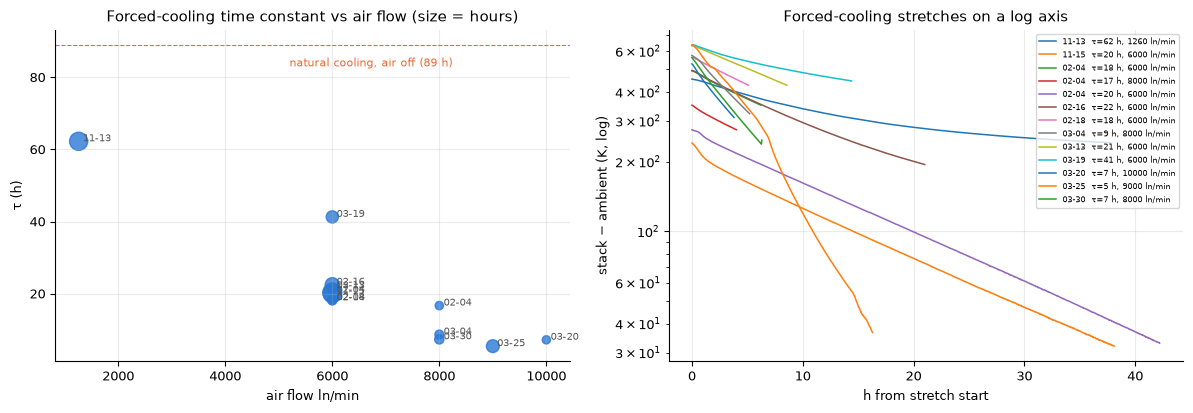

,stretches,tau_median_h,tau_min_h,tau_max_h,T_air_in_median_C
air_flow,,,,,
1000.0,1,62.2,62.2,62.2,238.5
6000.0,7,20.3,18.2,41.3,375.3
8000.0,3,8.7,7.3,16.7,297.9
9000.0,1,5.4,5.4,5.4,146.8
10000.0,1,7.2,7.2,7.2,348.7


In [12]:
good = fits[fits.R2 >= 0.9]
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].scatter(
    good.air_flow, good.tau_h, s=20 + good.hours * 4, color="#2a78d6", alpha=0.8
)
for _, r in good.iterrows():
    ax[0].text(r.air_flow + 80, r.tau_h, f"{r.start:%m-%d}", fontsize=7, color="#555")
ax[0].axhline(TAU_NATURAL_H, color="#eb6834", lw=0.8, ls="--")
ax[0].text(
    5200,
    TAU_NATURAL_H - 6,
    "natural cooling, air off (89 h)",
    fontsize=8,
    color="#eb6834",
)
ax[0].set_xlabel("air flow ln/min")
ax[0].set_ylabel("τ (h)")
ax[0].set_title("Forced-cooling time constant vs air flow (size = hours)")
for _, r in good.iterrows():
    g = s.loc[r.start : r.start + pd.Timedelta(hours=r.hours)]
    hh = (g.index - g.index[0]).total_seconds() / 3600
    ax[1].plot(
        hh,
        g.T_stack_C - g.T_amb_C.mean(),
        lw=1.1,
        label=f"{r.start:%m-%d}  τ={r.tau_h:.0f} h, {r.air_flow:.0f} ln/min",
    )
ax[1].set_yscale("log")
ax[1].set_xlabel("h from stretch start")
ax[1].set_ylabel("stack − ambient (K, log)")
ax[1].set_title("Forced-cooling stretches on a log axis")
ax[1].legend(fontsize=6)
fig.tight_layout()
fig.savefig(OUT / "forced_cooling_tau.png", dpi=130)
plt.show()
by_air = good.groupby(good.air_flow.round(-3)).agg(
    stretches=("tau_h", "size"),
    tau_median_h=("tau_h", "median"),
    tau_min_h=("tau_h", "min"),
    tau_max_h=("tau_h", "max"),
    T_air_in_median_C=("T_air_in_C", "median"),
)
by_air.round(1)

## 6. Air, gas and heater sequence on the way down

For each Cool-down episode, minutes from the first Shut-down minute to each switch, and the stack temperature there:

| Event | Test |
|---|---|
| heater off | EAPH < 0.2 kW (first minute after the last minute on) |
| natural gas off | FIRC 1.4 < 5 ln/min |
| forming gas on / off | N₂ (FIRC 1.3) > 1 / ≤ 1 ln/min; H₂ (FIRC 1.5) > 0.5 / ≤ 0.5 ln/min |
| air off | FIRC 1.1.1 + 1.1.2 ≤ 50 ln/min |

The window runs from 60 min before the episode to 6 h after its end, so the air-off that ends a cool-down and starts
the natural-cooling tail is included. An *off* switch counts only when it lasts ≥ 30 min, so the few minutes of
all-off during an emergency stop (2026-03-25 15:28) are not read as the end of the air. `N2_on = before` means the
forming gas was already on when the shut-down began (it ran through Hot standby). NaN = not seen in the window.

In [13]:
def first_after(mask, t0, n=1):
    """First minute at or after t0 that starts a run of at least n minutes of mask."""
    m = mask[mask.index >= t0]
    run = (m != m.shift()).cumsum()
    ok = m & (m.groupby(run).transform("size") >= n)
    return ok.index[ok.values.argmax()] if ok.any() else None


rows = []
for _, r in cd.iterrows():
    t0 = r.start
    w = d.loc[t0 - pd.Timedelta("60min") : r.end + pd.Timedelta("6h")]
    row = {
        "episode_id": r.episode_id,
        "prev": r.prev_stage,
        "trip": r.trip_initiated,
        "T_start_C": round(r.T_start_C, 0),
    }
    ev_ = {
        "heater_off": w.P_EAPH_kW < ops.EAPH_ON_W / 1000,
        "NG_off": w.fuel < 5,
        "N2_on": w.N2 > 1,
        "H2_off": w.H2 <= 0.5,
        "N2_off": w.N2 <= 1,
        "air_off": w.air_flow <= 50,
    }
    for k, m in ev_.items():
        before = m.loc[: t0 - pd.Timedelta("1min")]
        if k == "N2_on" and len(before) and before.iloc[-1]:
            row["N2_on_min"], row["T_at_N2_on_C"] = "before", np.nan
            continue
        if k in ("NG_off", "heater_off") and m.loc[:t0].iloc[-1]:
            # already off at the first Shut-down minute: take the last switch before it
            b = m.loc[:t0]
            sw = b.index[b & ~b.shift(fill_value=True)]
            t = sw[-1] if len(sw) else None
        else:
            t = first_after(m, t0, n=30 if k.endswith("_off") else 5)
        row[f"{k}_min"] = (
            round((t - t0).total_seconds() / 60) if t is not None else np.nan
        )
        row[f"T_at_{k}_C"] = round(w.T_stack_C.asof(t), 0) if t is not None else np.nan
    row["air_flow_median"] = w.air_flow[(w.index >= t0) & (w.air_flow > 50)].median()
    rows.append(row)
seq = pd.DataFrame(rows).set_index("episode_id")
seq.to_csv(OUT / "gas_sequence.csv")
seq

,prev,trip,T_start_C,heater_off_min,T_at_heater_off_C,NG_off_min,T_at_NG_off_C,N2_on_min,T_at_N2_on_C,H2_off_min,T_at_H2_off_C,N2_off_min,T_at_N2_off_C,air_off_min,T_at_air_off_C,air_flow_median
episode_id,,,,,,,,,,,,,,,,
20251113_2132_Shut-down,Start-up,False,472.0,-41,475.0,NaN,NaN,before,NaN,2286.0,260.0,2286.0,260.0,6361.0,25.0,5999.533333
20260130_1910_Shut-down,Start-up,False,240.0,2,240.0,NaN,NaN,898,226.0,0.0,240.0,0.0,240.0,116.0,198.0,5999.966667
20260204_0201_Shut-down,Hot standby,False,509.0,-7,510.0,NaN,NaN,before,NaN,632.0,288.0,632.0,288.0,3332.0,46.0,6000.050000
20260216_1037_Shut-down,Hot standby,False,510.0,-13,510.0,NaN,NaN,before,NaN,1263.0,210.0,1263.0,210.0,1263.0,210.0,6000.005787
20260218_1726_Shut-down,Hot standby,False,600.0,87,579.0,NaN,NaN,before,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6000.033333
20260304_1756_Shut-down,Hot standby,False,614.0,51,589.0,NaN,NaN,before,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8000.000000
20260313_1343_Shut-down,Part load,True,679.0,3,685.0,3.0,685.0,2,683.0,NaN,NaN,NaN,NaN,NaN,NaN,6000.016667
20260319_1549_Shut-down,Part load,True,631.0,7,647.0,6.0,646.0,6,646.0,NaN,NaN,NaN,NaN,NaN,NaN,6000.016667
20260320_1624_Shut-down,Thermal adjustment,False,572.0,42,543.0,NaN,NaN,before,NaN,388.0,292.0,388.0,292.0,NaN,NaN,10000.143519


**Where the cool-down ends.** The stack temperature when the air goes off, and what comes next.

In [14]:
end = seq[["T_at_air_off_C", "air_off_min"]].join(
    cd.set_index("episode_id")[["next_stage", "T_end_C", "operations"]]
)
end["air_off_h"] = (pd.to_numeric(end.air_off_min) / 60).round(1)
end.drop(columns="air_off_min")

,T_at_air_off_C,next_stage,T_end_C,operations,air_off_h
episode_id,,,,,
20251113_2132_Shut-down,25.0,file edge,22.636667,Slow cool-down > Cool-down (air flow on) > Pla...,106.0
20260130_1910_Shut-down,198.0,Start-up,175.075833,Cool-down (air flow on) > Natural cooling (air...,1.9
20260204_0201_Shut-down,46.0,Start-up,45.282000,Cool-down (air flow on) > Plant off at ambient,55.5
20260216_1037_Shut-down,210.0,Start-up,191.117500,Cool-down (air flow on) > Natural cooling (air...,21.0
20260218_1726_Shut-down,NaN,file edge,442.377500,Cool-down (air flow on),NaN
20260304_1756_Shut-down,NaN,file edge,336.314167,Cool-down (air flow on),NaN
20260313_1343_Shut-down,NaN,file edge,443.632500,Load ramp-down to zero > Cool-down (air flow on),NaN
20260319_1549_Shut-down,NaN,Start-up,459.246667,Load ramp-down to zero > Cool-down (air flow o...,NaN
20260320_1624_Shut-down,NaN,file edge,280.488333,Cool-down (air flow on) > Controlled cool-down...,NaN


## 7. Thermal gradient while cooling

On a cool-down the cold air enters on the inlet side, so the inlet-side thermocouples (`TIR_4_6_1…8`) **lag**:
their lead becomes negative. Same definitions as in the start-up notebook.

In [15]:
grad = (
    s[s.kind == "Cool-down"]
    .groupby("episode_id")
    .agg(
        spread_median_K=("T_spread_K", "median"),
        spread_max_K=("T_spread_K", "max"),
        inlet_lead_median_K=("T_inlet_lead_K", "median"),
        inlet_lead_min_K=("T_inlet_lead_K", "min"),
    )
)
grad = grad.loc[[i for i in sd.episode_id if i in grad.index]]
grad.round(1).to_csv(OUT / "thermal_gradient.csv")
grad.round(1)

,spread_median_K,spread_max_K,inlet_lead_median_K,inlet_lead_min_K
episode_id,,,,
20251113_2132_Shut-down,8.5,101.2,-3.7,-80.3
20260130_1910_Shut-down,8.8,39.5,2.0,-32.2
20260204_0201_Shut-down,11.0,64.4,-6.6,-58.2
20260216_1037_Shut-down,26.6,64.3,-21.8,-57.7
20260218_1726_Shut-down,62.6,79.8,-54.2,-71.2
20260304_1756_Shut-down,80.7,116.3,-65.3,-100.1
20260313_1343_Shut-down,68.4,109.7,-56.1,-85.7
20260319_1549_Shut-down,47.6,108.6,-40.1,-76.5
20260320_1624_Shut-down,66.4,104.6,-48.1,-91.8


inlet lead ≈ -13.1 + 1.19 K per °C/h of rate (R² 0.52)


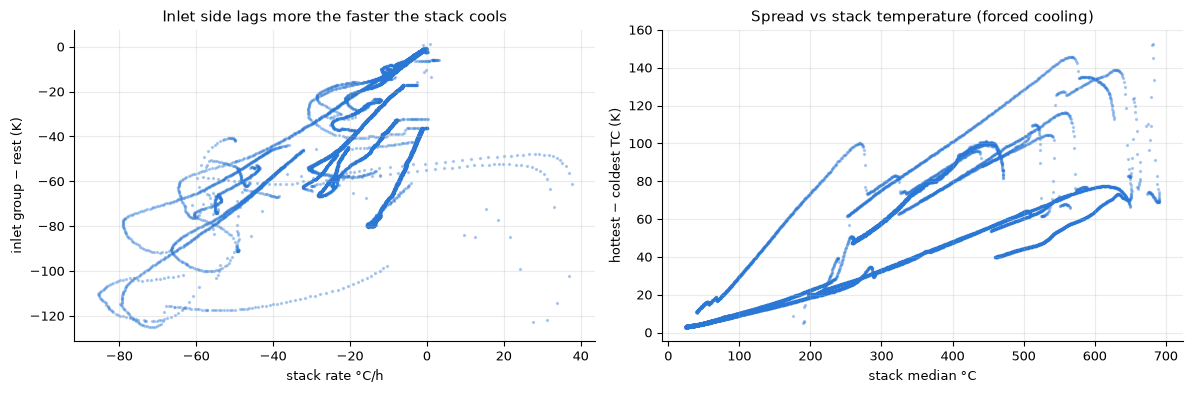

In [16]:
xx = fc[["dTdt_C_per_h", "T_inlet_lead_K", "T_spread_K", "T_stack_C"]].dropna()
k_lead = np.polyfit(xx.dTdt_C_per_h, xx.T_inlet_lead_K, 1)
print(
    f"inlet lead ≈ {k_lead[1]:.1f} + {k_lead[0]:.2f} K per °C/h of rate (R² "
    f"{np.corrcoef(xx.dTdt_C_per_h, xx.T_inlet_lead_K)[0, 1] ** 2:.2f})"
)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(xx.dTdt_C_per_h, xx.T_inlet_lead_K, s=2, color="#2a78d6", alpha=0.3)
ax[0].set_xlabel("stack rate °C/h")
ax[0].set_ylabel("inlet group − rest (K)")
ax[0].set_title("Inlet side lags more the faster the stack cools")
ax[1].scatter(xx.T_stack_C, xx.T_spread_K, s=2, color="#2a78d6", alpha=0.3)
ax[1].set_xlabel("stack median °C")
ax[1].set_ylabel("hottest − coldest TC (K)")
ax[1].set_title("Spread vs stack temperature (forced cooling)")
fig.tight_layout()
fig.savefig(OUT / "thermal_gradient.png", dpi=130)
plt.show()

## 8. Timings

In [17]:
dur = sd.groupby("kind")[["duration_h", "cooling_h", "at_ambient_h"]].agg(
    ["count", "min", "median", "max", "sum"]
)
print(dur.round(1).to_string())
tm = cd[
    [
        "episode_id",
        "start",
        "end",
        "duration_h",
        "cooling_h",
        "trip_initiated",
        "ends_at_run_edge",
    ]
].assign(
    begin_clock=cd.start.dt.strftime("%H:%M"), end_clock=cd.end.dt.strftime("%H:%M")
)
tm.to_csv(OUT / "timings.csv", index=False)
tm

          duration_h                           cooling_h                           at_ambient_h                        
               count  min median    max    sum     count  min median    max    sum        count  min median   max   sum
kind                                                                                                                   
Cool-down         11  5.6   13.0  122.5  301.7        11  5.6   13.0  106.0  281.2           11  0.0    0.0  16.5  20.5
Plant off          8  6.6   10.5   14.5   83.8         8  0.0    0.0   10.4   26.7            8  0.0    9.6  14.5  57.1


,episode_id,start,end,duration_h,cooling_h,trip_initiated,ends_at_run_edge,begin_clock,end_clock
5,20251113_2132_Shut-down,2025-11-13 21:32:00,2025-11-19 00:00:00,122.47,106.00,False,True,21:32,00:00
8,20260130_1910_Shut-down,2026-01-30 19:10:00,2026-01-31 08:09:00,12.98,12.98,False,False,19:10,08:09
15,20260204_0201_Shut-down,2026-02-04 02:01:00,2026-02-06 13:27:00,59.43,55.37,False,False,02:01,13:27
20,20260216_1037_Shut-down,2026-02-16 10:37:00,2026-02-17 16:56:00,30.32,30.32,False,False,10:37,16:56
25,20260218_1726_Shut-down,2026-02-18 17:26:00,2026-02-19 00:00:00,5.60,5.60,False,True,17:26,00:00
35,20260304_1756_Shut-down,2026-03-04 17:56:00,2026-03-05 00:00:00,6.07,6.07,False,True,17:56,00:00
43,20260313_1343_Shut-down,2026-03-13 13:43:00,2026-03-14 00:00:00,10.28,10.28,True,True,13:43,00:00
51,20260319_1549_Shut-down,2026-03-19 15:49:00,2026-03-20 06:30:00,14.68,14.68,True,False,15:49,06:30
56,20260320_1624_Shut-down,2026-03-20 16:24:00,2026-03-21 00:00:00,7.60,7.60,False,True,16:24,00:00
78,20260325_1514_Shut-down,2026-03-25 15:14:00,2026-03-26 13:03:00,21.82,21.82,True,False,15:14,13:03


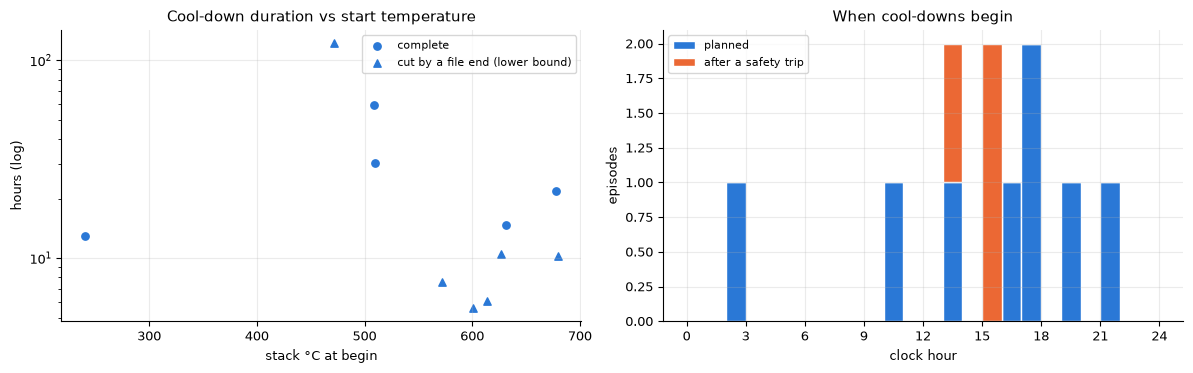

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for cut, mk in ((False, "o"), (True, "^")):
    xx = cd[cd.ends_at_run_edge == cut]
    ax[0].scatter(
        xx.T_start_C,
        xx.duration_h,
        color=KIND_COLORS["Cool-down"],
        marker=mk,
        s=28,
        label="cut by a file end (lower bound)" if cut else "complete",
    )
ax[0].set_yscale("log")
ax[0].set_xlabel("stack °C at begin")
ax[0].set_ylabel("hours (log)")
ax[0].set_title("Cool-down duration vs start temperature")
ax[0].legend(fontsize=8)
hb = np.arange(0, 25, 1)
ax[1].hist(
    [
        cd[~cd.trip_initiated].start.dt.hour
        + cd[~cd.trip_initiated].start.dt.minute / 60,
        cd[cd.trip_initiated].start.dt.hour
        + cd[cd.trip_initiated].start.dt.minute / 60,
    ],
    bins=hb,
    color=[KIND_COLORS["Cool-down"], "#eb6834"],
    label=["planned", "after a safety trip"],
    edgecolor="white",
    stacked=True,
)
ax[1].set_xticks(range(0, 25, 3))
ax[1].set_xlabel("clock hour")
ax[1].set_ylabel("episodes")
ax[1].set_title("When cool-downs begin")
ax[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUT / "timings.png", dpi=130)
plt.show()

## 9. Signal levels by temperature band

Median levels during the forced-cooling minutes of Cool-down episodes **at the usual 6 000 ln/min air** (the
8 000–10 000 ln/min cool-downs of March are faster, §4–5), per 50 K band of the stack median, and the per-minute
noise σ (robust, as in the other notebooks).

In [19]:
LEV = {
    "cool-down rate °C/h": "dTdt_C_per_h",
    "air ln/min": "air_flow",
    "PIR_2_02": "P_air_in",
    "N2 ln/min": "N2",
    "H2 ln/min": "H2",
    "EAPH kW": "P_EAPH_kW",
    "cathode inlet TIRC_2_06 °C": "TIRC_2_06",
    "TC spread K": "T_spread_K",
    "inlet lead K": "T_inlet_lead_K",
    "afterburner TIRC_5_09 °C": "TIRC_5_09",
    "reformer in TIRC_3_07 °C": "TIRC_3_07",
    "roof exhaust TIR_7_05 °C": "TIR_7_05",
}
fc6 = fc[fc.air_flow.between(5500, 6500)]
band = pd.cut(fc6.T_stack_C, np.arange(0, 701, 50))
lev = fc6.groupby(band)[list(LEV.values())].median()
lev.columns = list(LEV)
lev.insert(0, "minutes", fc6.groupby(band).size())
lev.round(1).to_csv(OUT / "levels_by_band.csv")
lev.round(1)

,minutes,cool-down rate °C/h,air ln/min,PIR_2_02,N2 ln/min,H2 ln/min,EAPH kW,cathode inlet TIRC_2_06 °C,TC spread K,inlet lead K,afterburner TIRC_5_09 °C,reformer in TIRC_3_07 °C,roof exhaust TIR_7_05 °C
T_stack_C,,,,,,,,,,,,,
"(0, 50]",1958,-0.8,6000.0,3.5,0.0,0.0,0.0,32.7,3.7,-1.2,34.9,34.3,20.1
"(50, 100]",2281,-2.5,6000.0,3.8,0.0,0.0,0.0,65.3,6.7,-3.2,70.5,70.6,23.6
"(100, 150]",1154,-5.2,6000.0,4.4,0.0,0.0,0.0,114.4,11.8,-6.4,123.9,123.7,28.7
"(150, 200]",772,-7.8,6000.0,4.8,0.0,0.0,0.0,161.4,17.1,-10.0,175.6,172.6,33.8
"(200, 250]",882,-9.8,6000.0,5.5,0.0,0.0,0.0,202.5,22.9,-17.1,228.8,196.4,41.0
"(250, 300]",457,-11.9,6000.0,8.6,1199.8,60.0,0.1,244.3,29.1,-23.6,273.8,49.8,61.3
"(300, 350]",208,-14.4,6000.0,9.6,1200.0,60.0,0.1,288.2,36.6,-30.8,319.5,56.5,72.4
"(350, 400]",272,-18.6,6000.1,10.3,1200.0,60.0,0.1,334.0,44.6,-38.0,364.2,69.7,83.7
"(400, 450]",315,-21.7,6000.0,11.1,1200.0,60.0,0.0,374.6,52.0,-44.2,404.0,80.7,93.0


In [20]:
noise = pd.Series(
    {k: ss.robust_sigma(fc[c]) for k, c in LEV.items()}, name="noise_sigma_per_min"
)
noise.round(3).to_frame()

,noise_sigma_per_min
cool-down rate °C/h,0.050
air ln/min,0.839
PIR_2_02,0.010
N2 ln/min,0.021
H2 ln/min,0.000
EAPH kW,0.000
cathode inlet TIRC_2_06 °C,0.091
TC spread K,0.070
inlet lead K,0.031
afterburner TIRC_5_09 °C,0.094


## 10. Summary

In [21]:
summary = pd.Series(
    {
        "Shut-down minutes": (
            f"{len(s):,} ({len(s) / 60:.0f} h, {len(s) / len(d):.0%} of logged time)"
        ),
        "Episodes": ", ".join(f"{n} {k}" for k, n in sd.kind.value_counts().items()),
        "Sub-stage hours": ", ".join(
            f"{k} {v:.0f} h" for k, v in sub_h.total_h.items()
        ),
        "Cool-downs started by a safety trip": (
            f"{int(cd.trip_initiated.sum())} of {len(cd)}"
        ),
        "Stack at the switch to At ambient": (
            f"{amb.T_stack_C.min():.0f}–{amb.T_stack_C.max():.0f} °C "
            f"(ambient {amb.T_amb_C.min():.0f}–{amb.T_amb_C.max():.0f} °C)"
        ),
        "Band rate 600→500 / 500→400 °C, 6 000 ln/min": (
            f"{br[br.air_flow_median.round(-3) == 6000]['600->500'].median():.0f} / "
            f"{br[br.air_flow_median.round(-3) == 6000]['500->400'].median():.0f} °C/h"
        ),
        "Band rate 600→500 / 500→400 °C, ≥ 8 000 ln/min": (
            f"{br[br.air_flow_median >= 7900]['600->500'].median():.0f} / "
            f"{br[br.air_flow_median >= 7900]['500->400'].median():.0f} °C/h"
        ),
        "Forced cooling, coldest TC p5 / min": (
            f"{fc.dTmindt_C_per_h.quantile(0.05):.0f} / "
            f"{fc.dTmindt_C_per_h.min():.0f} °C/h"
        ),
        "Forced-cooling τ at 6 000 / ≥ 8 000 ln/min (median)": (
            f"{good[good.air_flow.round(-3) == 6000].tau_h.median():.0f} / "
            f"{good[good.air_flow >= 7900].tau_h.median():.0f} h "
            "(natural, air off: 89 h)"
        ),
        "Stack at air off": ", ".join(f"{v:.0f}" for v in seq.T_at_air_off_C.dropna())
        + " °C",
    },
    name="value",
)
summary.to_frame()

,value
Shut-down minutes,"23,131 (386 h, 42% of logged time)"
Episodes,"11 Cool-down, 8 Plant off"
Sub-stage hours,"Cooling 308 h, At ambient (plant off) 78 h"
Cool-downs started by a safety trip,3 of 11
Stack at the switch to At ambient,25–46 °C (ambient 8–17 °C)
"Band rate 600→500 / 500→400 °C, 6 000 ln/min",-24 / -25 °C/h
"Band rate 600→500 / 500→400 °C, ≥ 8 000 ln/min",-62 / -59 °C/h
"Forced cooling, coldest TC p5 / min",-43 / -123 °C/h
Forced-cooling τ at 6 000 / ≥ 8 000 ln/min (median),"20 / 7 h (natural, air off: 89 h)"
Stack at air off,"25, 198, 46, 210, 42, 261 °C"


### Findings

**How much and what kind**
- Shut-down covers **386 h (42 %)** of the 39 logged days in **19 episodes**: 11 cool-downs (302 h) and 8 plant-off
  episodes (84 h; studied in the plant-off notebook). The no-load cool-backs of a hot stack (about 19 h before) are
  now Thermal adjustment, see `thermal_adjustment_analysis.ipynb`.
- Sub-stages: **Cooling 308 h** (281 h inside cool-downs, 27 h of natural-cooling tails in plant-off episodes) and
  **At ambient (plant off) 78 h**.
- Cooling ends inside the data three times, at a stack of **25–46 °C** (ambient 8–17 °C). On 2025-11-18 the air ran
  until 25 °C, so At ambient only began 9 K above ambient; on 02-06 and 03-28 the switch came at the 30 K margin.
- Cool-downs start from Hot standby (4), from Part load (3, all after a safety trip), from a heat-up that stopped
  below Hot standby (2, 2025-11-13 and 2026-01-30: the Start-up → Shut-down arrows outside the design) and right
  after a Thermal adjustment re-heat (2, 03-20 and 03-30).
- **3 of the 11 cool-downs are started by a safety trip**, all in March (03-13, 03-19, 03-25). On 03-13 and 03-19
  the power is cut at the exhaust trip value (`TIRZ_8_1_10` 201–202 °C > 200 °C); on 03-25 the gas goes to purge and
  an EMERGENCY STOP follows 10 min later.

**Cool-down rate (§4)**
- The rate depends on the **air flow**. At the usual **6 000 ln/min** the stack cools at **−24 °C/h** from 600 to
  500 °C and **−25 °C/h** from 500 to 400 °C, then slows to −7…−19 °C/h at 400→300 °C and −6 °C/h at 200→100 °C.
  The four cool-downs at **8 000–10 000 ln/min** (03-04, 03-20, 03-25, 03-30) run **2–3× faster**: −53…−71 °C/h at
  600→500 °C and −50…−62 °C/h at 500→400 °C.
- Against the 120 °C/h limit: the stack median never cools faster than **86 °C/h**. The coldest thermocouple reaches
  p5 −43 °C/h and crosses −120 °C/h for **5 min only**, on 2026-03-25 (min −123 °C/h).

**Forced-cooling physics (§5)**
- With air on and the heater off the stack still follows Newton's law closely (R² 0.94–1.00 over 13 stretches of
  3.8–42 h). Time constant **τ ≈ 20 h at 6 000 ln/min** (18–41 h, 7 stretches) and **5–9 h at 8 000–10 000 ln/min**
  (one 17 h at 8 000 on 02-04), against **89 h** for natural cooling with the air off. The slow cool-down of
  2025-11-13 at ~1 260 ln/min gives 62 h.
- The faster March cool-downs also blow colder air: the cathode inlet sits at 147–369 °C during those stretches
  (median 323 °C) against a median 375 °C at 6 000 ln/min. So the effect is more than the flow alone, and τ should be
  chosen per regime, not from a single flow formula.

**Air, gas and heater sequence (§6)**
- **From Hot standby**: the heater ramps down or switches off at the start (−41 to +87 min around the first
  Shut-down minute). The forming gas (N₂ 1 200 + H₂ 60 ln/min) and the air stay on.
- **After a load trip**: within **2–7 min** the natural gas goes off, the forming gas comes back on as purge and
  the heater goes off.
- **Forming gas off**: N₂ and H₂ stop together at **210–292 °C** (five cool-downs). On 2026-03-25 they ran down to
  69 °C.
- **Air off**: two patterns. Either the air stops at **198–261 °C** (01-30, 02-16, 03-30), which starts the
  natural-cooling tail (τ 89 h). Or it runs until the stack is at **25–46 °C** (2025-11-13 after 106 h, 02-04 after
  55 h, 03-25 after 18.5 h).
- 2026-03-20 evening is a **controlled cool-down**: the heater holds the cathode inlet at 280 °C and the stack levels
  off at ~280–290 °C. The file of 03-21 is missing, and 03-22 starts with the stack at 274 °C under the same 280 °C
  target, so the plant was most likely **parked at ~280 °C** across the missing day.

**Thermal gradient (§7)**
- Cooling reverses the start-up gradient: the inlet-side thermocouples **lag** by −40 to −65 K (median) in the
  fast cool-downs, down to −125 K, and the spread reaches **100–153 K**, against 15 K in Hot standby.
  Inlet lead ≈ −13 K + 1.2 K per °C/h of rate (R² 0.52). This is the same 1.2 K per °C/h slope as on the heat-up.

**Timings (§8)**
- Cool-downs start at any hour (02:01–21:32). Six of the 11 are cut by the end of a file, so they lasted longer than
  logged. The complete ones last 13–59 h.

### For the synthetic-data generator
| Parameter | Value |
|---|---|
| Trigger | from Hot standby (planned), a Thermal adjustment re-heat, or a load trip (exhaust `TIRZ_8_1_10` ≥ 200 °C); after a trip: NG off, forming gas on, heater off within 2–7 min |
| Sub-stages | Cooling until the plant is off and the stack ≤ ambient + 30 K (ambient 8–17 °C), then At ambient (plant off) until the next Start-up |
| Cool-down curve | T = T_amb + (T₀ − T_amb)·exp(−t/τ); τ ≈ 20 h at 6 000 ln/min, 5–9 h at 8 000–10 000 ln/min |
| Band rates (6 000 ln/min) | −24 (600→500), −25 (500→400), −7…−19 (400→300), −6 (200→100), −3 (100→50) °C/h |
| Forming gas | N₂ 1 200 + H₂ 60 ln/min kept on, both off at 210–290 °C |
| Air | 6 000 ln/min (8 000–10 000 in late March); off at 200–260 °C (then τ 89 h) or held to 25–46 °C |
| Gradient | inlet lead ≈ −13 + 1.2 × rate (K, rate in °C/h); spread up to 100–150 K in fast cool-downs |
| Limits | stack median ≥ −86 °C/h; coldest TC p5 −43 °C/h |

Cool-backs and re-heats of a hot stack: see [`thermal_adjustment_analysis.ipynb`](thermal_adjustment_analysis.ipynb).

### Open points
1. **Two cooling regimes**: why were the late-March cool-downs run at 8 000–10 000 ln/min with colder inlet air? Is it
   an operator procedure, so that the generator should offer both regimes?
2. **Warm park at ~280 °C (03-20 → 03-22)**: it is split today between Shut-down (*Controlled cool-down*) and
   Start-up (*Heat-up*, 03-22). One label for the whole park, e.g. a *Warm hold* operation?
3. **Air-off temperature**: 198–261 °C or near ambient. Confirm which is the standard procedure.